# 01 · Text → Embedding pipeline
Baseline for Milestone 1: turn COCO captions into the Transformer text embeddings that condition Stable Diffusion v1.5.
SD v1.5 uses the **CLIP ViT-L/14 text encoder** (12-layer Transformer): a caption → 77 token ids → a 77×768 hidden-state sequence, which the UNet reads through cross-attention.

In [1]:
import os, sys, json, torch, matplotlib.pyplot as plt
from transformers import CLIPTokenizer, CLIPTextModel
sys.path.append('../scripts'); from dataset import CocoPairs

DATA = os.environ.get('GP1_DATA', '/scratch/hu.zhim/gp1/data')
MODEL = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
tok = CLIPTokenizer.from_pretrained(MODEL, subfolder='tokenizer')
enc = CLIPTextModel.from_pretrained(MODEL, subfolder='text_encoder').to(device).eval()
print(device, '| params:', sum(p.numel() for p in enc.parameters()) / 1e6, 'M')

cuda | params: 123.06048 M


## 1. Tokenize one caption

In [2]:
rows = [json.loads(l) for l in open(f'{DATA}/train/metadata.jsonl')]
caption = rows[0]['text']
ids = tok(caption, padding='max_length', max_length=tok.model_max_length, truncation=True, return_tensors='pt').input_ids
print(caption)
print(ids.shape, tok.convert_ids_to_tokens(ids[0][:20]))

A cat sitting on a toilet seat drinking water from a toilet.
torch.Size([1, 77]) ['<|startoftext|>', 'a</w>', 'cat</w>', 'sitting</w>', 'on</w>', 'a</w>', 'toilet</w>', 'seat</w>', 'drinking</w>', 'water</w>', 'from</w>', 'a</w>', 'toilet</w>', '.</w>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>']


## 2. Encode → embeddings
`last_hidden_state` (77×768) is what SD conditions on; `pooler_output` (768, the EOS token) is a single-vector summary used here for similarity.

In [3]:
@torch.no_grad()
def embed(texts):
    t = tok(texts, padding='max_length', max_length=tok.model_max_length, truncation=True, return_tensors='pt').to(device)
    out = enc(**t)
    return out.last_hidden_state, out.pooler_output

seq, pooled = embed([caption])
print('sequence:', tuple(seq.shape), '| pooled:', tuple(pooled.shape))
# the empty prompt is the 'unconditional' embedding used by classifier-free guidance
print('empty-prompt sequence:', tuple(embed([''])[0].shape))

sequence: (1, 77, 768) | pooled: (1, 768)
empty-prompt sequence: (1, 77, 768)


## 3. Sanity check: semantic similarity
Captions about similar scenes should have higher cosine similarity than unrelated ones.

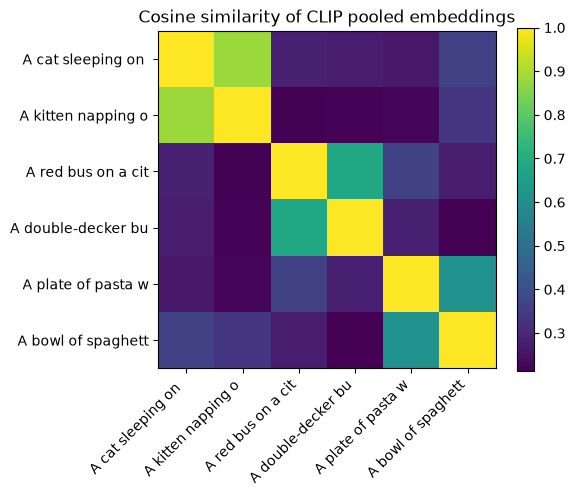

In [4]:
texts = ['A cat sleeping on a sofa', 'A kitten napping on a couch',
         'A red bus on a city street', 'A double-decker bus driving downtown',
         'A plate of pasta with tomato sauce', 'A bowl of spaghetti on a table']
p = torch.nn.functional.normalize(embed(texts)[1], dim=-1)
sim = (p @ p.T).cpu()
plt.figure(figsize=(6, 5)); plt.imshow(sim, cmap='viridis'); plt.colorbar()
plt.xticks(range(6), [t[:18] for t in texts], rotation=45, ha='right'); plt.yticks(range(6), [t[:18] for t in texts])
plt.title('Cosine similarity of CLIP pooled embeddings'); plt.tight_layout(); plt.show()

## 4. Preprocessed image–caption pairs
Images are 512×512 and normalized to [-1, 1] (the range SD's VAE expects).

5000 pairs | (3, 512, 512) | range -1.0 1.0


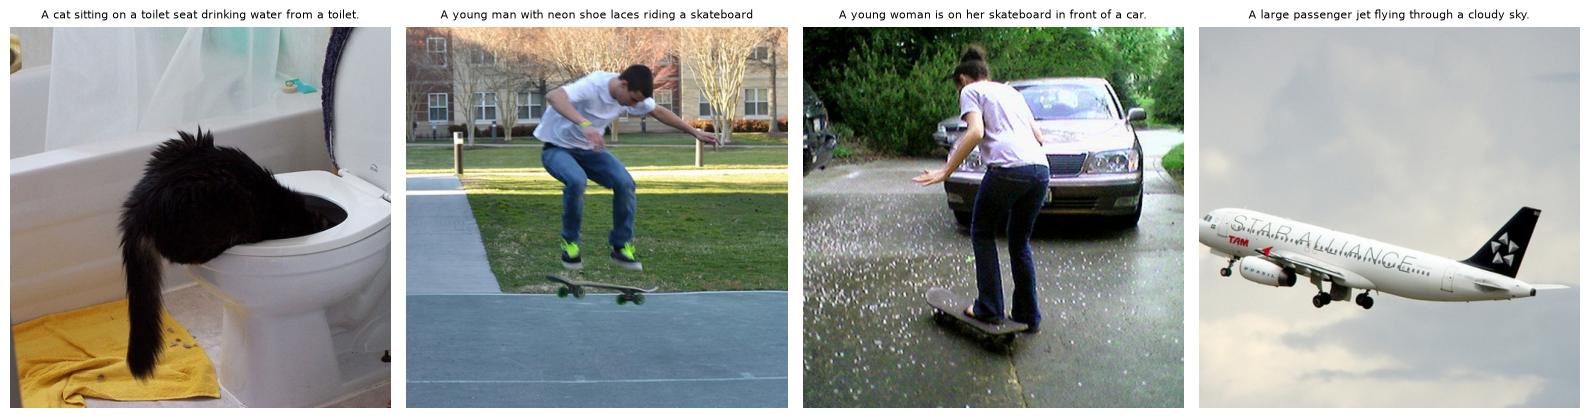

In [5]:
ds = CocoPairs(f'{DATA}/train', tok)
x = ds[0]
print(len(ds), 'pairs |', tuple(x['pixel_values'].shape), '| range', x['pixel_values'].min().item(), x['pixel_values'].max().item())
fig, ax = plt.subplots(1, 4, figsize=(16, 4.6))
for a, i in zip(ax, range(4)):
    s = ds[i]; a.imshow((s['pixel_values'].permute(1, 2, 0) + 1) / 2); a.axis('off'); a.set_title(s['text'], fontsize=8, wrap=True)
plt.tight_layout(); plt.show()

## 5. Embed the whole training set
Pre-computing the 77×768 embeddings once shows the pipeline scales to all 5000 captions.

In [6]:
from tqdm import tqdm
caps = [r['text'] for r in rows]
pooled_all = torch.cat([embed(caps[i:i+64])[1].cpu() for i in tqdm(range(0, len(caps), 64))])
print('pooled embeddings:', tuple(pooled_all.shape))

  0%|          | 0/79 [00:00<?, ?it/s]

  1%|▏         | 1/79 [00:00<00:08,  9.47it/s]

  3%|▎         | 2/79 [00:00<00:08,  9.56it/s]

  5%|▌         | 4/79 [00:00<00:07, 10.07it/s]

  8%|▊         | 6/79 [00:00<00:07, 10.38it/s]

 10%|█         | 8/79 [00:00<00:06, 10.58it/s]

... (33 outputs left out)

 96%|█████████▌| 76/79 [00:06<00:00, 11.06it/s]

 99%|█████████▊| 78/79 [00:07<00:00, 11.04it/s]

100%|██████████| 79/79 [00:07<00:00, 11.05it/s]

pooled embeddings: (5000, 768)
